# Industry Bias ABM - Convergence Analysis

Industry funding plays a vital role in biomedical research, but often introduces systematic biases that align study outcomes with commercial interests. Recent philosophical literature suggests treating funding disclosures as meta-evidence to quantitatively discount biased results. Using an agent-based model of scientific inquiry, we evaluate two active strategies for aggregating biased evidence: down-weighting industry results and dynamically adjusting them relative to publicly funded studies.

This notebook presents the analysis of the simulation results for three scenarios:
- **Base scenario**: Small study size.
- **Easy scenario**: A variation of the base scenario with larger studies, making it easier for agents to discover the truth.
- **Hard scenario**: An alternative scenario which is harder for agents because there are too many hypotheses to test.

The code below calculates convergence rates from the ABM simulation results and visualizes the impact of different industry bias styles across these three scenarios.


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast
import os

# Plotting style adjustments to match base_scenario_final.png
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.linestyle'] = ':'
plt.rcParams['grid.color'] = '#bbbbbb'
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16


In [22]:
def parse_set(s):
    if pd.isna(s): return set()
    if isinstance(s, set): return s
    s = str(s).strip()
    if s == 'set()': return set()
    if s.startswith('{') and s.endswith('}'):
        s_inner = s[1:-1]
        if not s_inner.strip():
            return set()
        return set(float(x.strip()) for x in s_inner.split(','))
    return set()

def load_and_preprocess(filepath):
    df = pd.read_csv(filepath)
    
    # Parse list and tuple columns
    df['bandits'] = df['bandits'].apply(ast.literal_eval)
    df['pub_bias'] = df['pub_bias'].apply(ast.literal_eval)
    df['site_bias'] = df['site_bias'].apply(ast.literal_eval)
    
    # Parse sets
    df['active_hypotheses'] = df['active_hypotheses'].apply(parse_set)
    
    # Extract industry bias values (index 1 of the tuple)
    df['pub_bias_ind'] = df['pub_bias'].apply(lambda x: x[1])
    df['site_bias_ind'] = df['site_bias'].apply(lambda x: x[1])
    
    # Best hypothesis is the max value in bandits
    df['best_hypothesis'] = df['bandits'].apply(max)
    
    # Check if converged in this specific round
    df['converged_round'] = df.apply(lambda row: len(row['active_hypotheses']) == 1 and row['best_hypothesis'] in row['active_hypotheses'], axis=1)
    
    # Create a unique run ID
    # (assuming round resets to 1 at the start of each new run)
    df['new_run_flag'] = (df['round'] == 1).astype(int)
    df['unique_run_id'] = df['new_run_flag'].cumsum()
    
    return df

In [23]:
def calculate_convergence_rate(df):
    # Determine which bias is varying
    unique_pub = df['pub_bias_ind'].nunique()
    unique_site = df['site_bias_ind'].nunique()
    
    if unique_pub > 1 and unique_site <= 1:
        bias_col = 'pub_bias_ind'
        bias_name = 'Publication bias'
    else:
        # For both design bias and industry selection, site_bias_ind varies.
        # We will default to 'Industry Selection / Design Bias' as title.
        bias_col = 'site_bias_ind'
        bias_name = 'Industry selection / Design bias'
            
    # A run is considered converged if in ALL of the last N rounds, public agents exclusively test the best hypothesis
    def run_converged(group):
        # Use last 45 rounds for base/easy, or last 4 for hard scenario (10 rounds total)
        n_rounds = 45 if len(group) >= 50 else 4
        last_n = group.tail(n_rounds)
        return last_n['converged_round'].all()
    
    runs = df.groupby('unique_run_id').apply(run_converged).reset_index(name='converged')
    
    # Merge back the style and bias level for each run
    run_info = df.groupby('unique_run_id').agg({
        'style': 'first',
        bias_col: 'first'
    }).reset_index()
    
    runs = pd.merge(runs, run_info, on='unique_run_id')
    
    # Calculate rate and standard deviation for Confidence Intervals
    rates = runs.groupby(['style', bias_col])['converged'].agg(['mean', 'count', 'std']).reset_index()
    
    # 95% Confidence Interval for a proportion/mean (1.96 * standard error)
    rates['ci'] = 1.96 * rates['std'] / np.sqrt(rates['count'])
    rates['ci'] = rates['ci'].fillna(0) # Handle NaN if count is 1
    
    rates['converged'] = rates['mean'] * 100 # percentage
    rates['ci'] *= 100 # percentage CI
    
    return rates, bias_col, bias_name

In [24]:
def plot_convergence(rates, bias_col, bias_name, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
        
    # Map styles to friendly names as per the chart
    style_mapping = {
        'adaptive_adjustment': 'Relative adjustment',
        'down_weighing_neutral': 'Downweighing',
        'down_weighing': 'Downweighing', # fallback if used
        'ignore': 'Ignoring industry',
        'normal': 'No adjustment',
        'Solomon': 'Solomon' # Optional if it's in the data
    }
    
    rates['Style Name'] = rates['style'].map(lambda x: style_mapping.get(x, x))
    
    # Define styles to match base_scenario_final.png
    plot_styles = {
        'Relative adjustment': {'marker': 'o', 'color': 'black', 'ls': '-', 'lw': 1.5},
        'Downweighing': {'marker': 's', 'color': '#333333', 'ls': '--', 'lw': 1.5},
        'Ignoring industry': {'marker': '^', 'color': '#666666', 'ls': '-.', 'lw': 1.5},
        'No adjustment': {'marker': 'D', 'color': '#999999', 'ls': ':', 'lw': 1.5},
        'Solomon': {'marker': 'p', 'color': '#444444', 'ls': '-', 'lw': 1.5}
    }
    
    # Standardize order if possible
    order = ['Relative adjustment', 'Downweighing', 'Ignoring industry', 'No adjustment', 'Solomon']
    existing_styles = [s for s in order if s in rates['Style Name'].values]
    # Add any styles not in standard order
    existing_styles += [s for s in rates['Style Name'].unique() if s not in existing_styles]
    
    for style_name in existing_styles:
        subset = rates[rates['Style Name'] == style_name]
        if subset.empty: continue
            
        opts = plot_styles.get(style_name, {'marker': 'o', 'color': 'black', 'ls': '-', 'lw': 1.5})
        ax.errorbar(subset[bias_col], subset['converged'], yerr=subset['ci'], 
                 marker=opts['marker'], color=opts['color'], 
                 linestyle=opts['ls'], linewidth=opts['lw'],
                 label=style_name, markersize=6, capsize=4)
    
    ax.set_xlabel('Industry Bias', fontsize=18)
    ax.set_ylabel('Correct Convergence Rate (%)', fontsize=18)
    ax.set_title(bias_name, fontsize=20, pad=10)
    ax.set_ylim(-5, 105)
    ax.legend(frameon=False, fontsize=16)
    
    return ax

## Generate Plots for Scenarios
This block iterates through the three scenarios, loads the corresponding result files (if they exist), calculates convergence rates, and saves a chart for each scenario.

Processing hard scenario...


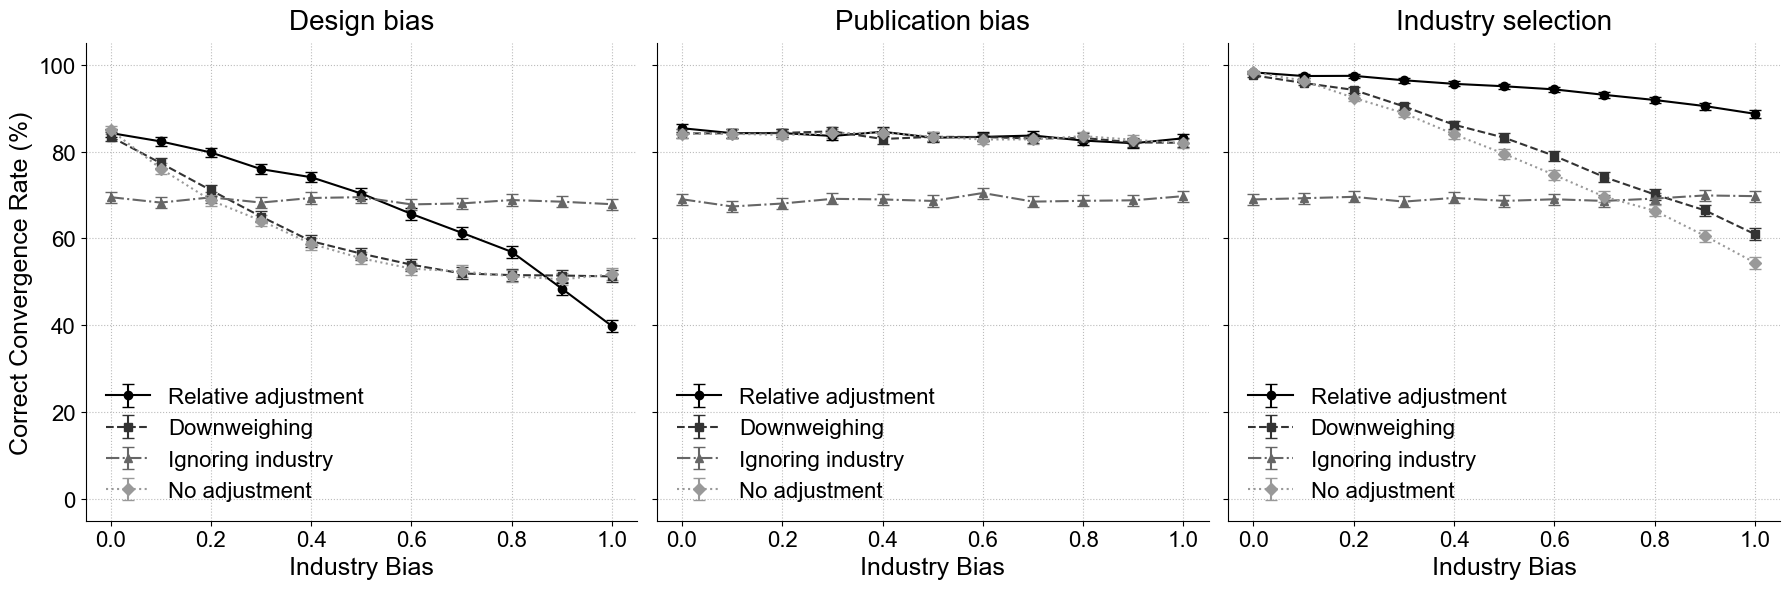

In [ ]:
# Define the scenarios and their corresponding result files
scenarios = {
     'base': {
         'Design bias': 'base_sitebias.csv',
         'Publication bias': 'base_pubbias.csv',
         'Industry selection': 'base_indselect.csv'
     },
     'easy': {
         'Design bias': 'easy_sitebias.csv',
         'Publication bias': 'easy_pubbias.csv',
         'Industry selection': 'easy_indselect.csv'
    },
    'hard': {
        'Design bias': 'hard_sitebias.csv',
        'Publication bias': 'hard_pubbias.csv',
        'Industry selection': 'hard_indselect.csv'
    }
}

for scenario_name, files in scenarios.items():
    print(f"Processing {scenario_name} scenario...")
    existing_files = {k: v for k, v in files.items() if os.path.exists(v)}
    
    if existing_files:
        fig, axes = plt.subplots(1, len(existing_files), figsize=(6 * len(existing_files), 6), sharey=True)
        if len(existing_files) == 1:
            axes = [axes]
        
        for i, (title, filepath) in enumerate(existing_files.items()):
            df = load_and_preprocess(filepath)
            rates, bias_col, _ = calculate_convergence_rate(df)
            plot_convergence(rates, bias_col, title, ax=axes[i])
            if i > 0:
                axes[i].set_ylabel('') # Only show y-label on the first subplot

        plt.tight_layout()
        plt.savefig(f'{scenario_name}.png', dpi=800, bbox_inches='tight', format='png')
        plt.show()
    else:
        print(f"  -> No result files found for {scenario_name} scenario. Make sure to add them to the directory.\n")
